# Сверточные нейронные сети

В данной работе мы рассмотрим бинарный классификатор. Изображения были загружены с конкурса <a href="https://www.kaggle.com/competitions/dogs-vs-cats-redux-kernels-edition/data">Kaggle Dogs vs Cats Redux Edition</a>. В наборе 25 000 изображений собак и кошек.

Библиотечки:

In [1]:
import numpy as np
import pandas as pd
import os
import random
import time

import torch
import torchvision
import torch.nn as nn
import torchvision.datasets as datasets
from torchvision import datasets, transforms
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

from sklearn.model_selection import train_test_split

from PIL import Image
import matplotlib.pyplot as plt

<p>Загрузка данных и предварительная обработка изображений.
<p>После загрузки данных, тренировочные изображения помещаются в папку train/ на локальном компьютере (мой вариант, вы сохраняете куда ваша душа пожелает). Далее анализируем папку train, получаем путь для каждого изображения и сохраняем его в списке img_files:

In [3]:
img_files = os.listdir('train/')
img_files = list(filter(lambda x: x != 'train', img_files))
def train_path(p): return f"train/{p}"
img_files = list(map(train_path, img_files))

print("total training images", len(img_files))
print("First item", img_files[0])

total training images 25000
First item train/cat.0.jpg


<p>Что мы видим:
<p>всего тренировочных изображений 25000.
<p>данные о первом элементе/train/cat.0.jpg

Прежде чем начать преобразовывать данные, наобходимо разделить набор данных на обучение и тест:

In [4]:
# create train-test split
random.shuffle(img_files)

train = img_files[:20000]
test = img_files[20000:]

print("train size", len(train))
print("test size", len(test))

train size 20000
test size 5000


Далее мы используем каждый путь для загрузки изображения, конвертируем его в RGB и маркируем изображение на основании его имени. Если в пути есть слово 'cat', то метка будет 0, иначе будет 1 для 'dog'. Для изображения требуется дополнительное преобразование, поэтому будет создан объект преобразования для изменения размера изображения до 244x244 и нормализации его значений. Класс 'CatDogDataset' получит набор данных (из torch.utils.data) и применит преобразование.

In [5]:
# image normalization
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# preprocessing of images
class CatDogDataset(Dataset):
    def __init__(self, image_paths, transform):
        super().__init__()
        self.paths = image_paths
        self.len = len(self.paths)
        self.transform = transform

    def __len__(self): return self.len

    def __getitem__(self, index): 
        path = self.paths[index]
        image = Image.open(path).convert('RGB')
        image = self.transform(image)
        label = 0 if 'cat' in path else 1
        return (image, label)

Воспользуемся классом 'CatDogDataset' для преобразования обучающих и тестовых наборов и преобразetv их в повторяемый набор данных, который PyTorch может использовать для обучения модели.

In [6]:
# create train dataset
train_ds = CatDogDataset(train, transform)
train_dl = DataLoader(train_ds, batch_size=100)
print(len(train_ds), len(train_dl))

# create test dataset
test_ds = CatDogDataset(test, transform)
test_dl = DataLoader(test_ds, batch_size=100)
print(len(test_ds), len(test_dl))

20000 200
5000 50


<p>Сверточная архитектура
<p>Рассмотрим архитектуру: 3 сверточных слоя и 3 полносявзных слоя. Эта архитектура не оптимальна, но служит для тестирования модели. Попробуйте поэксперементировать и изменить эту архитектуру (увеличить количество слоев, изменить глубину и т.д.), чтобы получить другие результаты.

In [7]:
class CatAndDogConvNet(nn.Module):

    def __init__(self):
        super().__init__()

        # onvolutional layers (3,16,32)
        self.conv1 = nn.Conv2d(in_channels = 3, out_channels = 16, kernel_size=(5, 5), stride=2, padding=1)
        self.conv2 = nn.Conv2d(in_channels = 16, out_channels = 32, kernel_size=(5, 5), stride=2, padding=1)
        self.conv3 = nn.Conv2d(in_channels = 32, out_channels = 64, kernel_size=(3, 3), padding=1)

        # conected layers
        self.fc1 = nn.Linear(in_features= 64 * 6 * 6, out_features=500)
        self.fc2 = nn.Linear(in_features=500, out_features=50)
        self.fc3 = nn.Linear(in_features=50, out_features=2)


    def forward(self, X):

        X = F.relu(self.conv1(X))
        X = F.max_pool2d(X, 2)

        X = F.relu(self.conv2(X))
        X = F.max_pool2d(X, 2)

        X = F.relu(self.conv3(X))
        X = F.max_pool2d(X, 2)

        X = X.view(X.shape[0], -1)
        X = F.relu(self.fc1(X))
        X = F.relu(self.fc2(X))
        X = self.fc3(X)

        return X

<p>Обучение модели
<p>Обратите внимание, что функции точности и потерь загружаются из библиотек PyTorch, а показатели производительности рассчитываются вручную.

In [8]:
# Create instance of the model
model = CatAndDogConvNet()

losses = []
accuracies = []
epoches = 8
start = time.time()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)

# Model Training...
for epoch in range(epoches):

    epoch_loss = 0
    epoch_accuracy = 0

    for X, y in train_dl:

        preds = model(X)
        loss = loss_fn(preds, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        accuracy = ((preds.argmax(dim=1) == y).float().mean())
        epoch_accuracy += accuracy
        epoch_loss += loss
        print('.', end='', flush=True)

    epoch_accuracy = epoch_accuracy/len(train_dl)
    accuracies.append(epoch_accuracy)
    epoch_loss = epoch_loss / len(train_dl)
    losses.append(epoch_loss)

    print("\n --- Epoch: {}, train loss: {:.4f}, train acc: {:.4f}, time: {}".format(epoch, epoch_loss, epoch_accuracy, time.time() - start))

    # test set accuracy
    with torch.no_grad():

        test_epoch_loss = 0
        test_epoch_accuracy = 0

        for test_X, test_y in test_dl:

            test_preds = model(test_X)
            test_loss = loss_fn(test_preds, test_y)

            test_epoch_loss += test_loss            
            test_accuracy = ((test_preds.argmax(dim=1) == test_y).float().mean())
            test_epoch_accuracy += test_accuracy

        test_epoch_accuracy = test_epoch_accuracy/len(test_dl)
        test_epoch_loss = test_epoch_loss / len(test_dl)

        print("Epoch: {}, test loss: {:.4f}, test acc: {:.4f}, time: {}\n".format(epoch, test_epoch_loss, test_epoch_accuracy, time.time() - start))

........................................................................................................................................................................................................
 --- Epoch: 0, train loss: 0.6248, train acc: 0.6395, time: 112.25749230384827
Epoch: 0, test loss: 0.5424, test acc: 0.7254, time: 133.7582015991211

........................................................................................................................................................................................................
 --- Epoch: 1, train loss: 0.5085, train acc: 0.7509, time: 229.838693857193
Epoch: 1, test loss: 0.4795, test acc: 0.7798, time: 249.19253015518188

........................................................................................................................................................................................................
 --- Epoch: 2, train loss: 0.4420, train acc: 0.7964, time: 355.78902983665466
Epoch: 2, test lo

<p>Epoch: 7, train loss: 0.2645, train acc: 0.8875, time: 1123.4351246356964
<p>Epoch: 7, test loss: 0.4904, test acc: 0.8034, time: 1144.6364653110504
<p>На тесте получили 0.8034, средненько, но с учетом всех обстоятельств - норм. Если у вас будет меньше 70, то стоит подшаманить. Сдавать надо с точностью больше 70 (кхе).

<p>Прогнозы
<p>Мы будем повторно использовать CatDogDataset для создания класса TestCatDogDataset, который в значительной степени делает то же самое, но возвращает объект изображения и идентификатор файла, поскольку папка test/ содержит набор немаркированных изображений.

In [9]:
test_files = os.listdir('test/')
test_files = list(filter(lambda x: x != 'test', test_files))
def test_path(p): return f"test/{p}"
test_files = list(map(test_path, test_files))

class TestCatDogDataset(Dataset):
    def __init__(self, image_paths, transform):
        super().__init__()
        self.paths = image_paths
        self.len = len(self.paths)
        self.transform = transform

    def __len__(self): return self.len

    def __getitem__(self, index): 
        path = self.paths[index]
        image = Image.open(path).convert('RGB')
        image = self.transform(image)
        fileid = path.split('/')[-1].split('.')[0]
        return (image, fileid)

test_ds = TestCatDogDataset(test_files, transform)
test_dl = DataLoader(test_ds, batch_size=100)
len(test_ds), len(test_dl)

(12500, 125)

С этого момента, вариативность выполнения задания). Можете сделать рандомный загрузчик. Это чисто на показать результаты.

Сделаем прогнозы для всего неразмеченного набора тестов из папки test/. Мы сохраним вероятности изображения собаки P(Image|dog) в списке dog_probs:

In [10]:
dog_probs = []

with torch.no_grad():
    for X, fileid in test_dl:
        preds = model(X)
        preds_list = F.softmax(preds, dim=1)[:, 1].tolist()
        dog_probs += list(zip(list(fileid), preds_list))

Давайте напечатаем 5 лучших изображений:

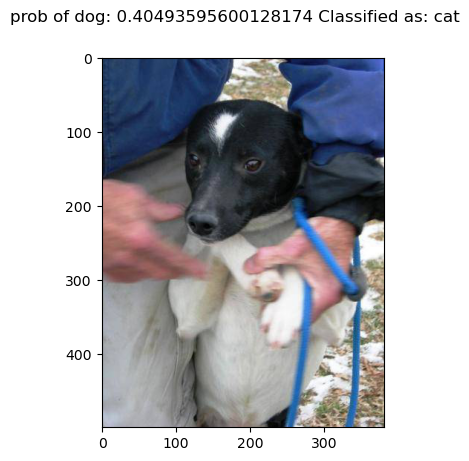

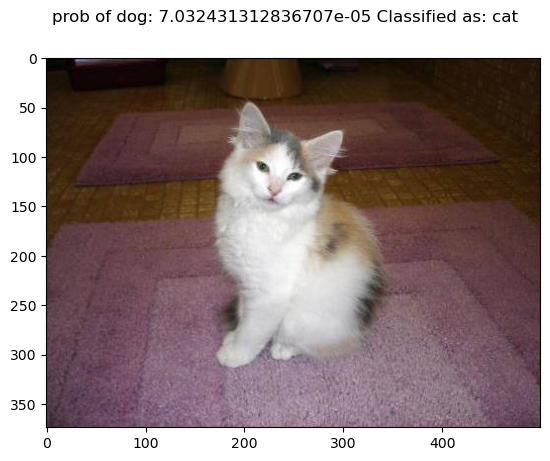

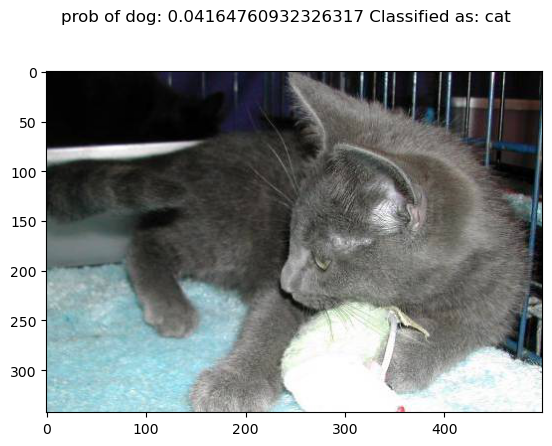

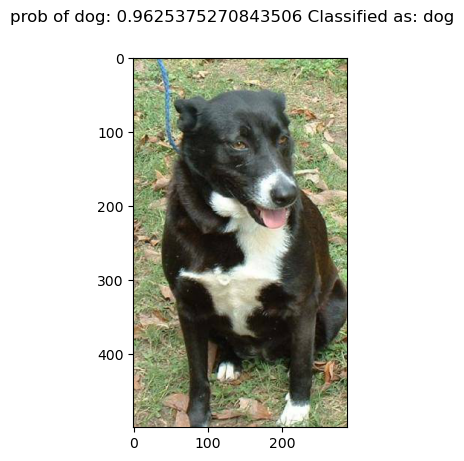

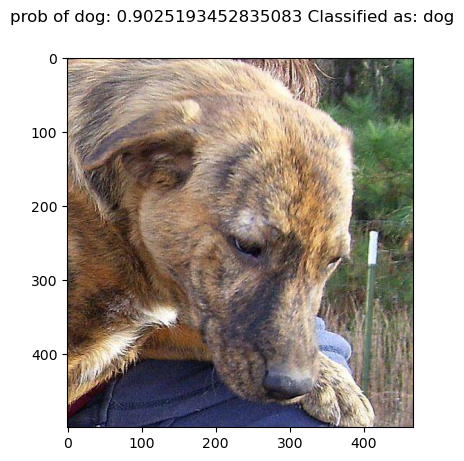

In [11]:
# display some images
for img, probs in zip(test_files[:5], dog_probs[:5]):
    pil_im = Image.open(img, 'r')
    label = "dog" if probs[1] > 0.5 else "cat"
    title = "prob of dog: " + str(probs[1]) + " Classified as: " + label
    plt.figure()
    plt.imshow(pil_im)
    plt.suptitle(title)
    plt.show()